# Live solar-generation inference

Fetch weather, build the trained feature contract, forecast the next 24 hourly timestamps, explain every prediction, and save one complete forecast release.

In [1]:
TRACKING_URI = "http://127.0.0.1:5001"
MODEL_URI = "models:/m-0eed3692206b4f9d8b3d82ac6dcca89c"
CAPACITY_FILE = "data/raw/2022-01-01_2026-10-18/mastr.parquet"
CAPACITY_SNAPSHOT_DATE = "2026-10-18"
OUTPUT_DIR = "data/predictions"
HORIZON_HOURS = 24

In [2]:
import json
import sys
from hashlib import sha256
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import requests
import shap
from IPython.display import display
from lightgbm import LGBMRegressor
from mlflow import sklearn as mlflow_sklearn
from mlflow.artifacts import load_dict
from mlflow.environment_variables import MLFLOW_ENABLE_PROXY_MULTIPART_DOWNLOAD
from mlflow.models import get_model_info

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

In [3]:
from services.mcp.app.data_sources.calendar_features import (
    prepare_german_calendar_features,
)
from services.mcp.app.data_sources.open_meteo import POINTS, VARIABLES
from services.mcp.app.data_sources.solar_features import prepare_pvlib_solar_features

## Fix the release time and model

Each execution creates one release. The default starts at the next whole UTC hour. The logged model URI pins the selected model; no registry alias is changed. This notebook runs once and does not schedule hourly execution.

In [4]:
issued_at = pd.Timestamp.now(tz="UTC")
start = issued_at.ceil("h")
hours = pd.date_range(start, periods=HORIZON_HOURS, freq="h").as_unit("ns")
assert HORIZON_HOURS == 24
release_id = issued_at.strftime("%Y-%m-%d_%H-%M-%S")
RELEASE_DIR = ROOT / OUTPUT_DIR / release_id
RELEASE_DIR.mkdir(parents=True, exist_ok=False)
print("Issued at:", issued_at)
print("Forecast timestamps:", hours[0], "to", hours[-1])

Issued at: 2026-10-19 10:44:52.336355+00:00
Forecast timestamps: 2026-10-19 11:00:00+00:00 to 2026-10-20 10:00:00+00:00


In [5]:
MLFLOW_ENABLE_PROXY_MULTIPART_DOWNLOAD.set(False)
mlflow.set_tracking_uri(TRACKING_URI)
model_info = get_model_info(MODEL_URI)
assert model_info.run_id is not None
source_run = mlflow.MlflowClient().get_run(model_info.run_id)
contract = load_dict(f"runs:/{model_info.run_id}/features.json")
FEATURES = contract["features"]
model = mlflow_sklearn.load_model(MODEL_URI)
assert isinstance(model, LGBMRegressor)
assert model.feature_name_ == FEATURES
explainer = shap.TreeExplainer(
    model, feature_perturbation="tree_path_dependent", model_output="raw"
)

## Read the latest known installed capacity

Use the last saved capacity at or before release time and hold it constant across the forecast. The snapshot date is explicit provenance, not the last timestamp in the hourly file. Refresh MaStR separately; no registry download is performed here.

In [6]:
capacity_path = ROOT / CAPACITY_FILE
capacity = pd.read_parquet(capacity_path)
capacity["timestamp_utc"] = pd.to_datetime(capacity.timestamp_utc, utc=True).dt.as_unit(
    "ns"
)
assert not capacity.timestamp_utc.isna().any()
assert not capacity.timestamp_utc.duplicated().any()
known = capacity.loc[capacity.timestamp_utc.le(issued_at)].sort_values("timestamp_utc")
assert not known.empty
latest_capacity = known.iloc[-1]
capacity_mw = float(latest_capacity.installed_pv_capacity_mw)
assert np.isfinite(capacity_mw) and capacity_mw > 0
snapshot_date = pd.Timestamp(CAPACITY_SNAPSHOT_DATE).date()
assert snapshot_date <= issued_at.tz_convert("Europe/Berlin").date()
capacity_age_days = (issued_at.tz_convert("Europe/Berlin").date() - snapshot_date).days
print(
    f"Installed capacity: {capacity_mw:,.2f} MW; snapshot age: {capacity_age_days} days"
)

Installed capacity: 116,134.63 MW; snapshot age: 1 days


## Fetch live hourly weather

Request the same ten locations and variables as training in one multi-location request. Preserve Open-Meteo hourly labels and the original hourly radiation variables; do not silently replace them with instantaneous radiation. Retrieval time is recorded; it is not a weather-model initialization time.

In [7]:
weather_params = {
    "latitude": ",".join(str(point[0]) for point in POINTS.values()),
    "longitude": ",".join(str(point[1]) for point in POINTS.values()),
    "hourly": ",".join(VARIABLES),
    "timezone": "GMT",
    "start_hour": hours[0].strftime("%Y-%m-%dT%H:%M"),
    "end_hour": hours[-1].strftime("%Y-%m-%dT%H:%M"),
    "wind_speed_unit": "kmh",
    "temperature_unit": "celsius",
    "precipitation_unit": "mm",
}
response = requests.get(
    "https://api.open-meteo.com/v1/forecast", params=weather_params, timeout=60
)
response.raise_for_status()
payload = response.json()
weather_retrieved_at = pd.Timestamp.now(tz="UTC")
assert isinstance(payload, list) and len(payload) == len(POINTS)
frames = []
for (name, (latitude, longitude)), item in zip(POINTS.items(), payload, strict=True):
    assert not item.get("error"), item
    assert item["utc_offset_seconds"] == 0
    frame = pd.DataFrame(item["hourly"])
    frame["timestamp_utc"] = pd.to_datetime(frame.pop("time"), utc=True).dt.as_unit(
        "ns"
    )
    frame["location"] = name
    frame["latitude"] = latitude
    frame["longitude"] = longitude
    frames.append(frame)
weather = pd.concat(frames, ignore_index=True)
assert not weather.duplicated(["timestamp_utc", "location"]).any()
for name, frame in weather.groupby("location"):
    assert pd.DatetimeIndex(frame.timestamp_utc).equals(hours), name
assert np.isfinite(weather[VARIABLES].to_numpy()).all()
assert (
    weather[
        [
            "shortwave_radiation",
            "direct_radiation",
            "diffuse_radiation",
            "precipitation",
            "wind_speed_10m",
        ]
    ]
    .ge(0)
    .all()
    .all()
)
cloud_columns = [column for column in VARIABLES if column.startswith("cloud_cover")]
assert (
    weather[cloud_columns].ge(0).all().all()
    and weather[cloud_columns].le(100).all().all()
)
weather.head()

,shortwave_radiation,direct_radiation,diffuse_radiation,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high,temperature_2m,precipitation,wind_speed_10m,timestamp_utc,location,latitude,longitude
0,368.0,214.0,154.0,100,53,0,100,11.8,0.0,14.1,2026-10-19 11:00:00+00:00,Hamburg,53.55,10.0
1,322.0,150.0,172.0,100,75,0,100,12.0,0.0,14.8,2026-10-19 12:00:00+00:00,Hamburg,53.55,10.0
2,307.0,148.0,159.0,100,38,0,100,12.1,0.0,14.8,2026-10-19 13:00:00+00:00,Hamburg,53.55,10.0
3,256.0,124.0,132.0,100,30,0,100,11.8,0.0,14.4,2026-10-19 14:00:00+00:00,Hamburg,53.55,10.0
4,151.0,58.0,93.0,100,50,0,100,11.3,0.0,13.3,2026-10-19 15:00:00+00:00,Hamburg,53.55,10.0


## Prepare exactly the trained features

Reuse the calendar and pvlib preparation functions with temporary files. Aggregate weather as in notebook 03 and select only the forecast hours. No intermediate calendar, solar, or feature files are retained.

In [8]:
start_date = hours[0].date().isoformat()
end_date = hours[-1].date().isoformat()
with TemporaryDirectory() as folder:
    calendar = prepare_german_calendar_features(
        start_date, end_date, folder, "calendar.parquet"
    )
    solar = prepare_pvlib_solar_features(start_date, end_date, folder, "solar.parquet")
weather_columns = sorted(VARIABLES)
grouped = weather.groupby("timestamp_utc")
weather_mean = (
    grouped[weather_columns].mean().add_prefix("weather_").add_suffix("_mean")
)
weather_max = grouped[cloud_columns].max().add_prefix("weather_").add_suffix("_max")
weather_hourly = weather_mean.join(weather_max).reset_index()
calendar_columns = calendar.select_dtypes(include="number").columns.tolist()
features = pd.DataFrame({"timestamp_utc": hours})
features["installed_pv_capacity_mw"] = capacity_mw
for frame in [calendar[["timestamp_utc", *calendar_columns]], solar, weather_hourly]:
    frame["timestamp_utc"] = pd.to_datetime(frame.timestamp_utc, utc=True).dt.as_unit(
        "ns"
    )
    features = features.merge(
        frame, on="timestamp_utc", how="left", validate="one_to_one"
    )
assert set(features.columns) == {"timestamp_utc", *FEATURES}
X = features[FEATURES]
assert len(X) == HORIZON_HOURS
assert np.isfinite(X.to_numpy()).all()
assert pd.DatetimeIndex(features.timestamp_utc).equals(hours)
features.head()

,timestamp_utc,installed_pv_capacity_mw,hour_local,day_of_year,month,weekday,is_weekend,is_holiday_de,hour_sin,hour_cos,...,weather_diffuse_radiation_mean,weather_direct_radiation_mean,weather_precipitation_mean,weather_shortwave_radiation_mean,weather_temperature_2m_mean,weather_wind_speed_10m_mean,weather_cloud_cover_max,weather_cloud_cover_low_max,weather_cloud_cover_mid_max,weather_cloud_cover_high_max
0,2026-10-19 11:00:00+00:00,116134.631935,13,292,10,0,0,0,-0.258819,-0.965926,...,141.89,241.21,0.0,383.1,12.80,10.98,100,94,0,100
1,2026-10-19 12:00:00+00:00,116134.631935,14,292,10,0,0,0,-0.500000,-0.866025,...,148.40,232.50,0.0,380.9,13.32,11.74,100,75,0,100
2,2026-10-19 13:00:00+00:00,116134.631935,15,292,10,0,0,0,-0.707107,-0.707107,...,144.02,218.28,0.0,362.3,13.78,11.56,100,73,0,100
3,2026-10-19 14:00:00+00:00,116134.631935,16,292,10,0,0,0,-0.866025,-0.500000,...,120.47,166.53,0.0,287.0,13.92,11.38,100,92,0,100
4,2026-10-19 15:00:00+00:00,116134.631935,17,292,10,0,0,0,-0.965926,-0.258819,...,87.88,92.52,0.0,180.4,13.59,11.53,100,62,0,100


## Forecast and explain every hour

SHAP explains raw CF. The served forecast applies only a zero lower bound, with its adjustment recorded separately; it is an explicit experimental policy, not a validated accuracy improvement. No night-time rule or upper clipping is applied.

In [9]:
raw_cf = np.asarray(model.predict(X))
assert np.isfinite(raw_cf).all()
explained = explainer(X)
values = np.asarray(explained.values)
base_cf = np.asarray(explained.base_values)
np.testing.assert_allclose(base_cf + values.sum(axis=1), raw_cf, rtol=1e-5, atol=1e-7)
forecast_cf = np.maximum(raw_cf, 0)
forecast = pd.DataFrame(
    {
        "timestamp_utc": hours,
        "lead_hours": (hours - issued_at).total_seconds() / 3600,
        "installed_pv_capacity_mw": capacity_mw,
        "raw_cf": raw_cf,
        "forecast_cf": forecast_cf,
        "raw_mw": raw_cf * capacity_mw,
        "forecast_mw": forecast_cf * capacity_mw,
        "forecast_energy_mwh": forecast_cf * capacity_mw,
        "shap_base_cf": base_cf,
        "shap_base_mw": base_cf * capacity_mw,
        "lower_bound_adjustment_mw": (forecast_cf - raw_cf) * capacity_mw,
        "raw_cf_above_one": raw_cf > 1,
    }
)
contributions = pd.DataFrame(values, columns=FEATURES)
contributions.insert(0, "timestamp_utc", hours)
contributions = contributions.melt(
    id_vars="timestamp_utc", var_name="feature", value_name="shap_cf"
)
contributions["shap_mw"] = contributions.shap_cf * capacity_mw
contribution_sums = contributions.groupby("timestamp_utc").shap_mw.sum().reindex(hours)
np.testing.assert_allclose(
    forecast.shap_base_mw
    + contribution_sums.to_numpy()
    + forecast.lower_bound_adjustment_mw,
    forecast.forecast_mw,
    rtol=1e-5,
    atol=1e-6,
)
display(forecast)

,timestamp_utc,lead_hours,installed_pv_capacity_mw,raw_cf,forecast_cf,raw_mw,forecast_mw,forecast_energy_mwh,shap_base_cf,shap_base_mw,lower_bound_adjustment_mw,raw_cf_above_one
0,2026-10-19 11:00:00+00:00,0.252129,116134.631935,0.294476,0.294476,34198.917179,34198.917179,34198.917179,0.087271,10135.185608,0.000000,False
1,2026-10-19 12:00:00+00:00,1.252129,116134.631935,0.273659,0.273659,31781.311031,31781.311031,31781.311031,0.087271,10135.185608,0.000000,False
2,2026-10-19 13:00:00+00:00,2.252129,116134.631935,0.212854,0.212854,24719.755759,24719.755759,24719.755759,0.087271,10135.185608,0.000000,False
3,2026-10-19 14:00:00+00:00,3.252129,116134.631935,0.118931,0.118931,13812.044887,13812.044887,13812.044887,0.087271,10135.185608,0.000000,False
4,2026-10-19 15:00:00+00:00,4.252129,116134.631935,0.037825,0.037825,4392.843161,4392.843161,4392.843161,0.087271,10135.185608,0.000000,False
5,2026-10-19 16:00:00+00:00,5.252129,116134.631935,0.002194,0.002194,254.827902,254.827902,254.827902,0.087271,10135.185608,0.000000,False
6,2026-10-19 17:00:00+00:00,6.252129,116134.631935,0.000158,0.000158,18.329597,18.329597,18.329597,0.087271,10135.185608,0.000000,False
7,2026-10-19 18:00:00+00:00,7.252129,116134.631935,0.000559,0.000559,64.913283,64.913283,64.913283,0.087271,10135.185608,0.000000,False
8,2026-10-19 19:00:00+00:00,8.252129,116134.631935,0.000544,0.000544,63.210601,63.210601,63.210601,0.087271,10135.185608,0.000000,False
9,2026-10-19 20:00:00+00:00,9.252129,116134.631935,0.000539,0.000539,62.624899,62.624899,62.624899,0.087271,10135.185608,0.000000,False


## Inspect the forecast and hourly explanations

Energy values assume a one-hour duration. Timestamp labels and feature joins follow the same unchanged UTC timestamps as training. MW-scaled SHAP is conditional on the recorded capacity and does not attribute the external multiplication by capacity.

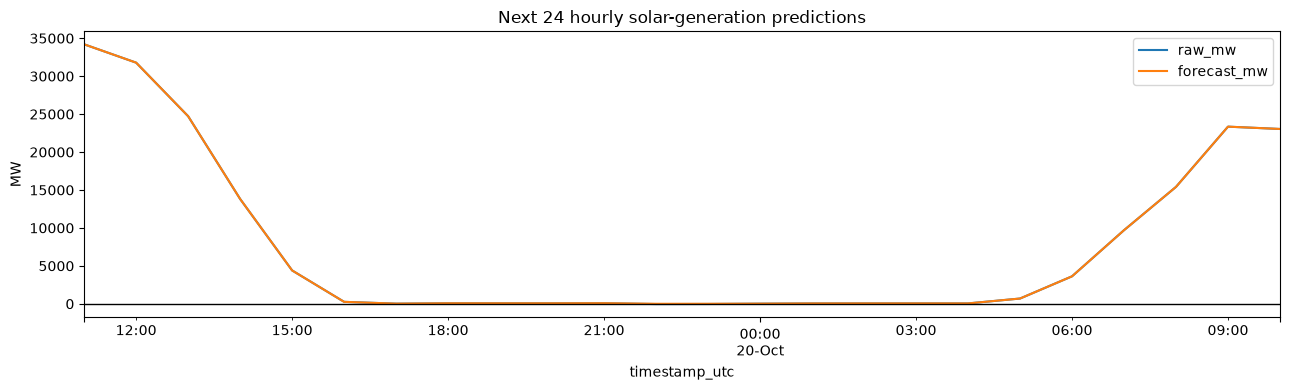

In [10]:
fig, ax = plt.subplots(figsize=(13, 4))
forecast.plot(x="timestamp_utc", y=["raw_mw", "forecast_mw"], ax=ax)
ax.set_ylabel("MW")
ax.set_title("Next 24 hourly solar-generation predictions")
ax.axhline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()
plt.close(fig)

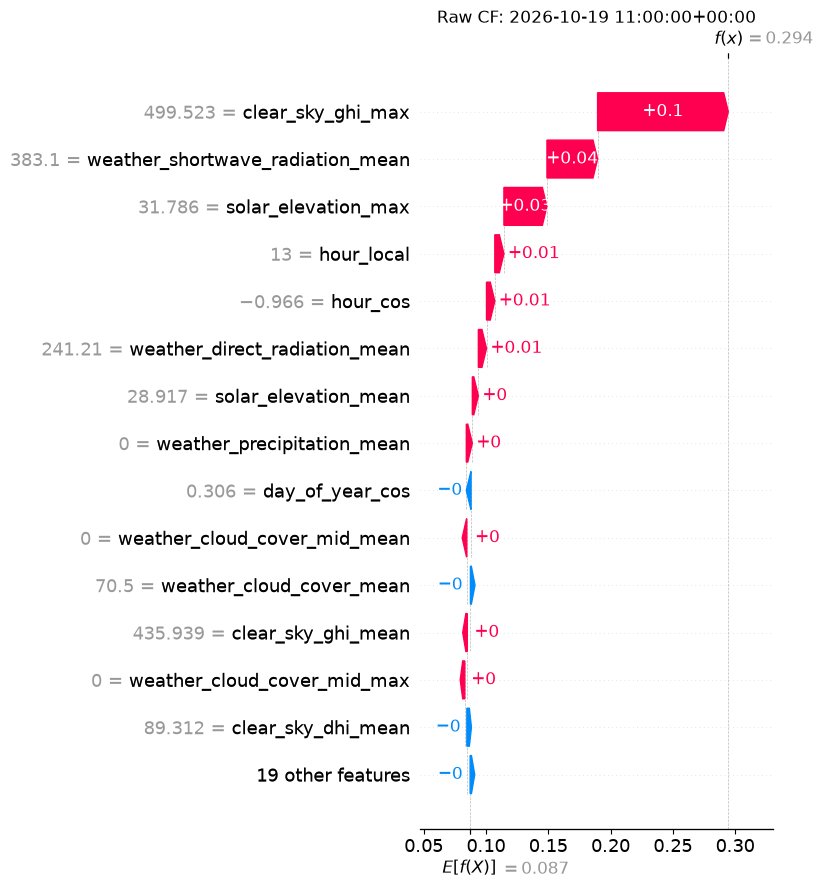

,timestamp_utc,feature,shap_cf,shap_mw
408,2026-10-19 11:00:00+00:00,clear_sky_ghi_max,0.104909,12183.595149
624,2026-10-19 11:00:00+00:00,weather_shortwave_radiation_mean,0.040646,4720.365366
384,2026-10-19 11:00:00+00:00,solar_elevation_max,0.034546,4011.998410
24,2026-10-19 11:00:00+00:00,hour_local,0.007310,848.892842
192,2026-10-19 11:00:00+00:00,hour_cos,0.006664,773.931197
576,2026-10-19 11:00:00+00:00,weather_direct_radiation_mean,0.006539,759.439882
264,2026-10-19 11:00:00+00:00,solar_elevation_mean,0.004842,562.288129
600,2026-10-19 11:00:00+00:00,weather_precipitation_mean,0.004826,560.464954
240,2026-10-19 11:00:00+00:00,day_of_year_cos,-0.003805,-441.940146
528,2026-10-19 11:00:00+00:00,weather_cloud_cover_mid_mean,0.003447,400.311098


In [11]:
hour_number = 0
assert 0 <= hour_number < HORIZON_HOURS
shap.plots.waterfall(explained[hour_number], max_display=15, show=False)
explanation_figure = plt.gcf()
plt.title(f"Raw CF: {hours[hour_number]}")
plt.tight_layout()
plt.show()
plt.close(explanation_figure)
contributions.loc[contributions.timestamp_utc.eq(hours[hour_number])].sort_values(
    "shap_cf", key=lambda column: column.abs(), ascending=False
).head(10)

## Save the forecast

Each UTC-named directory under data/predictions contains weather.parquet, forecast.parquet, and metadata.json. The forecast table includes input features and all SHAP contributions in CF, prefixed with shap_. Keep plots in the notebook. Publish latest.json only after saving and verifying the complete release.

In [12]:
shap_columns = pd.DataFrame(values, columns=[f"shap_{name}" for name in FEATURES])
shap_columns.insert(0, "timestamp_utc", hours)
result = forecast.merge(
    features.drop(columns="installed_pv_capacity_mw"),
    on="timestamp_utc",
    validate="one_to_one",
).merge(shap_columns, on="timestamp_utc", validate="one_to_one")
weather.to_parquet(RELEASE_DIR / "weather.parquet", index=False)
result.to_parquet(RELEASE_DIR / "forecast.parquet", index=False)
pd.testing.assert_frame_equal(pd.read_parquet(RELEASE_DIR / "forecast.parquet"), result)
metadata = {
    "release_id": release_id,
    "issued_at": issued_at.isoformat(),
    "completed_at": pd.Timestamp.now(tz="UTC").isoformat(),
    "model_uri": MODEL_URI,
    "model_id": model_info.model_id,
    "source_run_id": model_info.run_id,
    "feature_contract": contract,
    "preprocessing": "notebook_03_numeric_features_v1",
    "capacity_snapshot_date": CAPACITY_SNAPSHOT_DATE,
    "capacity_value_timestamp": latest_capacity.timestamp_utc.isoformat(),
    "capacity_file_sha256": sha256(capacity_path.read_bytes()).hexdigest(),
    "capacity_age_days": capacity_age_days,
    "capacity_mw": capacity_mw,
    "capacity_policy": "hold_last_known_value",
    "weather_url": "https://api.open-meteo.com/v1/forecast",
    "weather_parameters": weather_params,
    "weather_retrieved_at": weather_retrieved_at.isoformat(),
    "weather_run_time": None,
    "weather_units": [item["hourly_units"] for item in payload],
    "horizon_hours": HORIZON_HOURS,
    "first_timestamp_utc": hours[0].isoformat(),
    "last_timestamp_utc": hours[-1].isoformat(),
    "output_policy": "lower_bound_zero_v1",
    "shap_method": "tree_path_dependent",
    "shap_columns": shap_columns.columns.drop("timestamp_utc").tolist(),
    "shap_unit": "capacity_factor",
    "limitations": [
        "Historical model scores do not establish live 24-hour-ahead accuracy.",
        "Installed capacity is an operating-fleet snapshot held constant.",
        "SHAP explains raw CF; output adjustment is separate.",
    ],
}
(RELEASE_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
latest_path = ROOT / OUTPUT_DIR / "latest.json"
temporary = latest_path.with_suffix(".tmp")
temporary.write_text(
    json.dumps(
        {"release_id": release_id, "directory": str(RELEASE_DIR.relative_to(ROOT))},
        indent=2,
    )
    + "\n"
)
temporary.replace(latest_path)
print("Saved release:", RELEASE_DIR)

Saved release: /Users/denys/Projects/Academic/masters-thesis/data/predictions/2026-10-19_10-44-52


In [13]:
latest = json.loads((ROOT / OUTPUT_DIR / "latest.json").read_text())
saved = pd.read_parquet(ROOT / latest["directory"] / "forecast.parquet")
pd.testing.assert_frame_equal(saved, result)
saved.head()

,timestamp_utc,lead_hours,installed_pv_capacity_mw,raw_cf,forecast_cf,raw_mw,forecast_mw,forecast_energy_mwh,shap_base_cf,shap_base_mw,...,shap_weather_diffuse_radiation_mean,shap_weather_direct_radiation_mean,shap_weather_precipitation_mean,shap_weather_shortwave_radiation_mean,shap_weather_temperature_2m_mean,shap_weather_wind_speed_10m_mean,shap_weather_cloud_cover_max,shap_weather_cloud_cover_high_max,shap_weather_cloud_cover_low_max,shap_weather_cloud_cover_mid_max
0,2026-10-19 11:00:00+00:00,0.252129,116134.631935,0.294476,0.294476,34198.917179,34198.917179,34198.917179,0.087271,10135.185608,...,0.000034,0.006539,0.004826,0.040646,-0.000787,0.000341,-0.000227,-0.000035,-0.000112,0.002008
1,2026-10-19 12:00:00+00:00,1.252129,116134.631935,0.273659,0.273659,31781.311031,31781.311031,31781.311031,0.087271,10135.185608,...,0.000083,0.003845,0.003727,0.042030,-0.000469,0.000249,-0.000240,-0.000031,0.001392,0.001673
2,2026-10-19 13:00:00+00:00,2.252129,116134.631935,0.212854,0.212854,24719.755759,24719.755759,24719.755759,0.087271,10135.185608,...,-0.000363,0.005826,0.003758,0.026524,-0.000363,-0.000161,-0.000233,-0.000052,0.001304,0.001237
3,2026-10-19 14:00:00+00:00,3.252129,116134.631935,0.118931,0.118931,13812.044887,13812.044887,13812.044887,0.087271,10135.185608,...,0.000080,0.002579,0.003437,0.021505,-0.000400,-0.000115,-0.000203,-0.000076,-0.000004,0.001157
4,2026-10-19 15:00:00+00:00,4.252129,116134.631935,0.037825,0.037825,4392.843161,4392.843161,4392.843161,0.087271,10135.185608,...,-0.000413,0.001377,0.001567,-0.006547,-0.000404,-0.000092,-0.000202,-0.000078,0.000460,0.000845
